# Dissertation Preprocessing & Consolidation

## 1: Setup & Configuration

### 1.1: Import Necessary Libraries

In [114]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
from shapely.ops import nearest_points
import numpy as np

### 1.2: Define all File Paths

In [72]:
paths = {
    'census_2021': '/Users/callumhall/Documents/Dissertation/Datasets/Cleaned Data/cleaned_census.csv',
    'samhi': '/Users/callumhall/Documents/Dissertation/Datasets/Cleaned Data/cleaned_samhi_data.csv',
    'crime': '/Users/callumhall/Documents/Dissertation/Datasets/Cleaned Data/lsoa_level_crime_summary.csv',
    'hpi': '/Users/callumhall/Documents/Dissertation/Datasets/Cleaned Data/borough_level_hpi_summary.csv',
    'imd': '/Users/callumhall/Documents/Dissertation/Datasets/Cleaned Data/IMD_data.csv',
    'master_lookup': '/Users/callumhall/Documents/Dissertation/Datasets/master_lookup_2021_based.csv',
    'greenspace': '/Users/callumhall/Documents/Dissertation/Datasets/Greenspace Data/TQ_GreenspaceSite.shp',
    'shapefile': '/Users/callumhall/Documents/Dissertation/Datasets/LSOA Boundaries Shapefile/LSOA_2021_EW_BFE_V10.shp'
}

print("Phase 1: Setup Complete.")

Phase 1: Setup Complete.


### 1.3: Checking DF Info

In [75]:
print("--- DataFrame Information ---")

for name, path in paths.items():
    try:
        df = pd.read_csv(path)
        print(f"\n--- Info for: {name} ---")
        df.info()
    except Exception as e:
        print(f"\n--- Could not read {name}: {e} ---")

--- DataFrame Information ---

--- Info for: census_2021 ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4988 entries, 0 to 4987
Data columns (total 38 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Total_Population            4988 non-null   int64  
 1   Edu_No_Quals                4988 non-null   float64
 2   Edu_Level_1_Quals           4988 non-null   float64
 3   Edu_Level_2_Quals           4988 non-null   float64
 4   Edu_Apprentice              4988 non-null   float64
 5   Edu_Level_3_Quals           4988 non-null   float64
 6   Edu_Level_4_Plus            4988 non-null   float64
 7   LSOA_Code                   4988 non-null   object 
 8   Total_Households            4988 non-null   int64  
 9   Tenure_Owned                4988 non-null   float64
 10  Tenure_Social_Rented        4988 non-null   float64
 11  Tenure_Private_Rented       4988 non-null   float64
 12  Total_Employed              4

## 2: Data Consolidation

### 2.1: Load Lookups & Raw Shapefiles

In [46]:
df_master_lookup = pd.read_csv(paths['master_lookup'])
gdf_lsoas_england = gpd.read_file(paths['shapefile'])

### 2.2: Create London Shapefile

Used a lookup to create a list of London LSOA codes and filtered the shapefile down to `gdf_lsoas_england` for optimisation.

In [47]:
london_boroughs = ['Camden', 'Greenwich', 'Hackney', 'Hammersmith and Fulham', 'Islington', 'Kensington and Chelsea', 'Lambeth', 'Lewisham', 'Southwark', 'Tower Hamlets', 'Wandsworth', 'Westminster', 'Barking and Dagenham', 'Barnet', 'Bexley', 'Brent', 'Bromley', 'Croydon', 'Ealing', 'Enfield', 'Haringey', 'Harrow', 'Havering', 'Hillingdon', 'Hounslow', 'Kingston upon Thames', 'Merton', 'Newham', 'Redbridge', 'Richmond upon Thames', 'Sutton', 'Waltham Forest', 'City of London']
london_lookup = df_master_lookup[df_master_lookup['ladnm'].isin(london_boroughs)]
london_lsoa_codes = london_lookup['LSOA21CD'].unique()
gdf_lsoas_london = gdf_lsoas_england[gdf_lsoas_england['LSOA21CD'].isin(london_lsoa_codes)].copy()

### 2.3: Load all Individual Datasets

In [49]:
df_census = pd.read_csv(paths['census_2021'])
df_samhi = pd.read_csv(paths['samhi'])
df_crime = pd.read_csv(paths['crime'])
df_hpi = pd.read_csv(paths['hpi'])
df_imd = pd.read_csv(paths['imd'])

### 2.4: Preparing Datasets for Merging

In [52]:
# a) Create a clean LSOA-to-Borough lookup (one row per LSOA)
df_borough_lookup = london_lookup[['LSOA21CD', 'ladcd', 'ladnm']].drop_duplicates(subset=['LSOA21CD'])

# b) Rename the SAMHI LSOA column and drop duplicates
df_samhi.rename(columns={'LSOA21CD': 'LSOA_Code'}, inplace= True)
df_samhi_agg = df_samhi.drop_duplicates(subset=['LSOA_Code'])

# c) Ensure IMD data has one row per LSOA
df_imd_agg = df_imd.drop_duplicates(subset=['LSOA_Code'])

# d) Rename Column in Census
df_census.rename(columns={'Total_Households_x': 'Total_Households'}, inplace=True)

### 2.5: Merging all Datasets

In [54]:
master_gdf = gdf_lsoas_london.merge(df_borough_lookup, on='LSOA21CD', how='left')
master_gdf = master_gdf.merge(df_census, left_on='LSOA21CD', right_on='LSOA_Code', how='left')
master_gdf = master_gdf.merge(df_crime, left_on='LSOA21CD', right_on='LSOA code', how='left')
master_gdf = master_gdf.merge(df_samhi_agg, on='LSOA_Code', how='left')
master_gdf = master_gdf.merge(df_imd_agg, left_on='LSOA21CD', right_on='LSOA_Code', how='left')
master_gdf = master_gdf.merge(df_hpi, on='ladcd', how='left')

### 2.6: Final Cleanup

In [56]:
master_gdf.rename(columns={'ladnm': 'Borough'}, inplace=True)
master_gdf = master_gdf[master_gdf['Borough'] != 'City of London'].copy() # Exclude City of London
master_gdf['Total_Crimes_12m'] = master_gdf['Total_Crimes_12m'].fillna(0)
master_gdf = master_gdf.loc[:, ~master_gdf.columns.duplicated()] # Drop duplicated columns
master_gdf = master_gdf.drop(columns= 'LSOA21NMW')

# Final verification check
total_rows = len(master_gdf)
unique_lsoas = master_gdf['LSOA21CD'].nunique()

print("\n--- Verification ---")
print(f"Total rows in the final GeoDataFrame: {total_rows}")
print(f"Number of unique LSOAs: {unique_lsoas}")
print("\n--- Null Value Check After Merging ---")
print(master_gdf.isnull().sum())
if total_rows == unique_lsoas:
    print("Success! Your data is at the LSOA level with no duplicates. ✅")
else:
    print("Warning: Duplicate rows still exist.")

print("\nData Consolidation Complete. Your 'master_gdf' is ready.")


--- Verification ---
Total rows in the final GeoDataFrame: 4805
Number of unique LSOAs: 4805

--- Null Value Check After Merging ---
LSOA21CD                      0
LSOA21NM                      0
BNG_E                         0
BNG_N                         0
LAT                           0
LONG                          0
GlobalID                      0
geometry                      0
ladcd                         0
Borough                       0
Total_Population              0
Edu_No_Quals                  0
Edu_Level_1_Quals             0
Edu_Level_2_Quals             0
Edu_Apprentice                0
Edu_Level_3_Quals             0
Edu_Level_4_Plus              0
LSOA_Code_x                   0
Total_Households              0
Tenure_Owned                  0
Tenure_Social_Rented          0
Tenure_Private_Rented         0
Total_Employed                0
Occ_Managers                  0
Occ_Professional              0
Occ_Associate_Professional    0
Occ_Skilled_Trades            0
To

In [58]:
master_gdf.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
Index: 4805 entries, 4 to 4810
Data columns (total 56 columns):
 #   Column                      Non-Null Count  Dtype   
---  ------                      --------------  -----   
 0   LSOA21CD                    4805 non-null   object  
 1   LSOA21NM                    4805 non-null   object  
 2   BNG_E                       4805 non-null   int64   
 3   BNG_N                       4805 non-null   int64   
 4   LAT                         4805 non-null   float64 
 5   LONG                        4805 non-null   float64 
 6   GlobalID                    4805 non-null   object  
 7   geometry                    4805 non-null   geometry
 8   ladcd                       4805 non-null   object  
 9   Borough                     4805 non-null   object  
 10  Total_Population            4805 non-null   float64 
 11  Edu_No_Quals                4805 non-null   float64 
 12  Edu_Level_1_Quals           4805 non-null   float64 
 13  Edu_Level_2_Qua

## 3: Feature Engineering

### 3.1: Setting Up Feature Engineering

In [61]:
from libpysal.weights import Queen

def engineer_confounders(gdf):
    """
    Engineer all confounder features for causal analysis.
    Input: LSOA-level GeoDataFrame (master_gdf)
    Output: GeoDataFrame with added confounder columns
    """
    # Make a copy to avoid SettingWithCopyWarning
    df = gdf.copy()

### 3.2. Socioeconomic Features

#### 3.2.1. Education

In [80]:
master_gdf['education_low'] = (master_gdf['Edu_No_Quals'] + master_gdf['Edu_Level_1_Quals']) / master_gdf['Total_Population']
master_gdf['education_high'] = master_gdf['Edu_Level_4_Plus'] / master_gdf['Total_Population']

#### 3.2.2. Employment Quality

In [83]:
master_gdf['professional_ratio'] = (master_gdf['Occ_Professional'] + master_gdf['Occ_Associate_Professional'] ) / master_gdf['Total_Employed']

#### 3.2.3. Housing Stress

In [86]:
master_gdf['rented_ratio'] = (master_gdf['Tenure_Private_Rented'] + master_gdf['Tenure_Social_Rented']) / master_gdf['Total_Households']

### 3.3. Urban Environment & Density

#### 3.3.1. Population Density

In [90]:
master_gdf['population_density'] = master_gdf['Total_Population'] / (master_gdf.geometry.area / 1_000_000)

#### 3.3.2. Housing Type

In [97]:
master_gdf['flat_ratio'] = master_gdf['Flats'] / master_gdf['Total_Properties']
master_gdf['house_ratio'] = (master_gdf['Property_Detached'] + master_gdf['Property_Semi'] + master_gdf['Property_Terraced']) / master_gdf['Total_Properties']

#### 3.3.3. Crime (Standardised)

In [101]:
master_gdf['crime_rate'] = (master_gdf['Total_Crimes_12m'] / master_gdf['Total_Population']) * 1000

### 3.4. Demographic Composition

#### 3.4.1. Age Structure

In [107]:
age_young = ['Age_15_19', 'Age_20_24', 'Age_25_29']
age_working = [f'Age_{i}_{i+4}' for i in range(20, 64, 5)]
age_elderly = ['Age_60_64']
    
master_gdf['pct_young'] = master_gdf[age_young].sum(axis=1) / master_gdf['Total_Age_Population']
master_gdf['pct_working_age'] = master_gdf[age_working].sum(axis=1) / master_gdf['Total_Age_Population']
master_gdf['pct_elderly'] = master_gdf[age_elderly].sum(axis=1) / master_gdf['Total_Age_Population']

#### 3.4.2. Ethnic Diversity

The Shannon Index was created with the help of Google Gemini 2.5 pro

In [116]:
master_gdf['Pct_Asian'] = master_gdf['Ethnic_Asian'] / master_gdf['Total_Population']
master_gdf['Pct_White'] = master_gdf['Ethnic_White'] / master_gdf['Total_Population']
master_gdf['Pct_Black'] = master_gdf['Ethnic_Black'] / master_gdf['Total_Population']

ethnic_cols = ['Ethnic_Asian', 'Ethnic_Black', 'Ethnic_Mixed', 'Ethnic_White']
ethnic_proportions = master_gdf[ethnic_cols].div(master_gdf['Total_Ethnic_Population'], axis=0)
master_gdf['ethnic_diversity'] = -np.sum(ethnic_proportions * np.log(ethnic_proportions + 1e-10), axis=1)

### 3.5. Spatial Confounders (Neighbourhood Effects)

#### 3.5.1. Create Spatial Weights Matrix

In [122]:
w = Queen.from_dataframe(master_gdf, use_index=False)

#### 3.5.2. Spatial Lag of Deprivation

In [130]:
master_gdf['IMD_neighborhood'] = pd.Series(w.sparse.toarray().dot(master_gdf['IMD_Score'].fillna(0)) / w.sparse.toarray().sum(axis=1))

#### 3.5.3. Spatial Lag of Crime

In [134]:
master_gdf['crime_neighborhood'] = pd.Series(w.sparse.toarray().dot(master_gdf['crime_rate'].fillna(0)) / w.sparse.toarray().sum(axis=1))

### 3.6: Engineering Greenspace Features

Calculated 3 greenspace metrics:

1. `distance_to_greenspace`
2. `greenspace_area_in_500m`
3. `greenspace_area_in_1000m`

Then added them into my `master_gdf` and saved the result in an EDA ready file.

#### 3.6.1: Preparing Geodataframes

In [136]:
# Load the greenspace shapefile
gdf_greenspace = gpd.read_file('/Users/callumhall/Documents/Dissertation/Datasets/Greenspace Data/TQ_GreenspaceSite.shp')

# Ensure both are in a projected CRS (e.g., British National Grid)
master_gdf = master_gdf.to_crs(epsg=27700)
gdf_greenspace = gdf_greenspace.to_crs(epsg=27700)

# Create a spatial index for the greenspace data for fast lookups
print("Building spatial index for greenspaces...")
greenspace_sindex = gdf_greenspace.sindex

print("Preparation complete.")

Building spatial index for greenspaces...
Preparation complete.


#### 3.6.2: Calculate Features

In [138]:
print("\n--- Calculating Greenspace Features (Optimized Method) ---")

# Prepare lists to store the results
distances = []
areas_500m = []
areas_1000m = []

# Get the centroids of all LSOAs once
lsoa_centroids = master_gdf.geometry.centroid

# Loop through each LSOA's centroid
for i, centroid in enumerate(lsoa_centroids):
    if (i + 1) % 500 == 0:
        print(f"Processing LSOA {i+1} of {len(lsoa_centroids)}...")

    # --- Step 1: Find nearby greenspaces efficiently ---
    possible_matches_index = list(greenspace_sindex.intersection(centroid.buffer(1500).bounds))
    nearby_greenspaces = gdf_greenspace.iloc[possible_matches_index]

    # --- Step 2: Calculate Distance ---
    if not nearby_greenspaces.empty:
        # THE FIX: Replace .unary_union with .union_all()
        nearest_geom = nearest_points(centroid, nearby_greenspaces.union_all())[1]
        distance = centroid.distance(nearest_geom)
        distances.append(distance)
    else:
        distances.append(None)

    # --- Step 3: Calculate Area in Buffers ---
    # 500m buffer
    buffer_500 = gpd.GeoSeries([centroid.buffer(500)], crs="EPSG:27700")
    # THE FIX: Replace .unary_union with .union_all()
    intersect_500 = nearby_greenspaces.intersection(buffer_500.union_all())
    areas_500m.append(intersect_500.area.sum())
    
    # 1000m buffer
    buffer_1000 = gpd.GeoSeries([centroid.buffer(1000)], crs="EPSG:27700")
    # THE FIX: Replace .unary_union with .union_all()
    intersect_1000 = nearby_greenspaces.intersection(buffer_1000.union_all())
    areas_1000m.append(intersect_1000.area.sum())


--- Calculating Greenspace Features (Optimized Method) ---
Processing LSOA 500 of 4805...
Processing LSOA 1000 of 4805...
Processing LSOA 1500 of 4805...
Processing LSOA 2000 of 4805...
Processing LSOA 2500 of 4805...
Processing LSOA 3000 of 4805...
Processing LSOA 3500 of 4805...
Processing LSOA 4000 of 4805...
Processing LSOA 4500 of 4805...


#### 3.6.3: Add New Features to Dataframe

In [140]:
print("\n--- Adding new features to the GeoDataFrame ---")

master_gdf['distance_to_greenspace'] = distances
master_gdf['greenspace_area_in_500m'] = areas_500m
master_gdf['greenspace_area_in_1000m'] = areas_1000m

# Fill any potential NaNs
master_gdf['distance_to_greenspace'] = master_gdf['distance_to_greenspace'].fillna(0)
master_gdf['greenspace_area_in_500m'] = master_gdf['greenspace_area_in_500m'].fillna(0)
master_gdf['greenspace_area_in_1000m'] = master_gdf['greenspace_area_in_1000m'].fillna(0)

print("All greenspace features engineered successfully.")


--- Adding new features to the GeoDataFrame ---
All greenspace features engineered successfully.


In [142]:
master_gdf.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
Index: 4805 entries, 4 to 4810
Data columns (total 77 columns):
 #   Column                      Non-Null Count  Dtype   
---  ------                      --------------  -----   
 0   LSOA21CD                    4805 non-null   object  
 1   LSOA21NM                    4805 non-null   object  
 2   BNG_E                       4805 non-null   int64   
 3   BNG_N                       4805 non-null   int64   
 4   LAT                         4805 non-null   float64 
 5   LONG                        4805 non-null   float64 
 6   GlobalID                    4805 non-null   object  
 7   geometry                    4805 non-null   geometry
 8   ladcd                       4805 non-null   object  
 9   Borough                     4805 non-null   object  
 10  Total_Population            4805 non-null   float64 
 11  Edu_No_Quals                4805 non-null   float64 
 12  Edu_Level_1_Quals           4805 non-null   float64 
 13  Edu_Level_2_Qua

#### 3.6.4. Advanced Spatial Features

In [152]:
# 1. Green Space Accessibility Index (Weighted by Population Density)
master_gdf['greenspace_accessibility'] = (
    master_gdf['greenspace_area_in_500m'] / 
    (master_gdf['distance_to_greenspace'] + 0.001)  # Avoid division by zero
) * np.log1p(master_gdf['population_density'])

# 2. Park Equity Score (Compare green space to deprivation)
master_gdf['park_equity'] = (
    master_gdf['greenspace_area_in_1000m'] / 
    (master_gdf['IMD_Score'] + 1)  # Higher score = more greenspace in deprived areas
)

### 3.7. Final Quality Checks

#### 3.7.1. Check for Low Variance Features

In [149]:
# Check for near-zero variance features (can destabilize models)
from sklearn.feature_selection import VarianceThreshold

numeric_data = master_gdf.select_dtypes(include=[np.number]).drop(columns=['BNG_E','BNG_N','LAT','LONG'])
selector = VarianceThreshold(threshold=0.01)  # Removes features with <1% variance
selector.fit(numeric_data)
low_variance = [col for col, mask in zip(numeric_data.columns, ~selector.get_support()) if mask]
print("Low-variance features:", low_variance)

Low-variance features: ['Income_Deprivation_Score', 'education_low', 'pct_young', 'pct_working_age', 'pct_elderly']


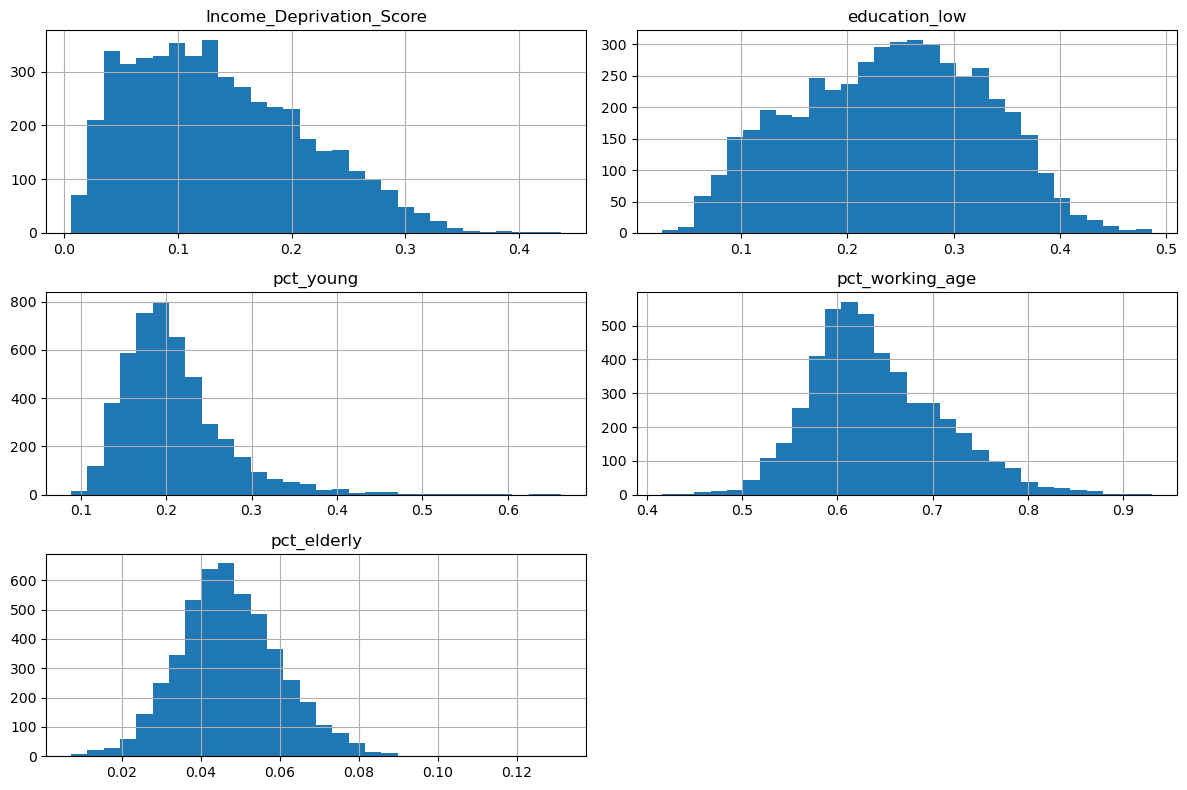

       Income_Deprivation_Score  education_low    pct_young  pct_working_age  \
count               4805.000000    4805.000000  4805.000000      4805.000000   
mean                   0.136197       0.240578     0.207569         0.640567   
std                    0.075592       0.087733     0.059655         0.068434   
min                    0.006000       0.025355     0.088275         0.415429   
1%                     0.018000       0.067220     0.117345         0.507060   
25%                    0.075000       0.173299     0.168391         0.593518   
50%                    0.125000       0.244261     0.197021         0.630360   
75%                    0.189000       0.308579     0.232572         0.683038   
99%                    0.321960       0.422358     0.408816         0.827458   
max                    0.437000       0.486500     0.662673         0.930410   

       pct_elderly  
count  4805.000000  
mean      0.047484  
std       0.013052  
min       0.007178  
1%        0.01

In [157]:
import matplotlib.pyplot as plt

# Plot distributions
low_var_features = ['Income_Deprivation_Score', 'education_low', 
                    'pct_young', 'pct_working_age', 'pct_elderly']
master_gdf[low_var_features].hist(bins=30, figsize=(12, 8))
plt.tight_layout()
plt.show()

# Check descriptive stats
print(master_gdf[low_var_features].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]))

In [159]:
# --- Save the result immediately ---
output_path = 'final_analysis_gdf.gpkg'
master_gdf.to_file(output_path, driver='GPKG')
print(f"\nFinal GeoDataFrame successfully saved to: {output_path}")


Final GeoDataFrame successfully saved to: final_analysis_gdf.gpkg
